In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

FIG_SIZE = (10, 8)
SIZE = 18
SIZE_SMALL = 15
FONT_SIZE = int(SIZE)
FONT_SIZE_SMALL = int(SIZE_SMALL)
FONT_WEIGHT = "bold"
MARKER_SIZE = 10
LINE_WIDTH = 2
GRID = True
ERRORBAR = ("ci", 95)

PLOT_DPI = 600
PLOT_FORMAT = "pdf"

rc = {
    "figure.figsize": FIG_SIZE,
    "figure.titlesize": 20,
    "axes.labelsize": FONT_SIZE,
    "axes.labelweight": FONT_WEIGHT,
    "legend.fontsize": FONT_SIZE_SMALL,
    "legend.title_fontsize": FONT_SIZE_SMALL,
    "xtick.labelsize": FONT_SIZE,
    "ytick.labelsize": FONT_SIZE,
    "lines.markersize": MARKER_SIZE,
    "lines.linewidth": LINE_WIDTH,
    "axes.titlesize": FONT_SIZE_SMALL,
    "axes.grid": GRID,
}

sns.set_theme(style="whitegrid", palette="colorblind", context="paper", rc=rc)

# Network-aware experiment analysis

This notebook reads `results.parquet`, checks dataset coverage, and compares the heuristics in terms of SCI, network contribution, computation time, and number of nodes used. Every figure is saved to `plots/` using the format configured in the previous cell.


In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
from matplotlib.patches import Patch
from IPython.display import display

WORKING_DIR = Path.cwd()
RESULTS_PATH = WORKING_DIR / "results.parquet"
PLOTS_DIR = WORKING_DIR / "plots"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)


def save_plot(name, figure=None):
    if figure is None:
        figure = plt.gcf()
        figure.tight_layout()
    path = PLOTS_DIR / f"{name}.{PLOT_FORMAT}"
    figure.savefig(path, dpi=PLOT_DPI, bbox_inches="tight")
    plt.show()
    plt.close(figure)
    print(f"Saved: {path}")


## Loading and preparation

Only successfully completed trials are retained. Aggregate component, network, total, and objective SCI values are derived from the four atomic SCI columns. The network share is computed relative to total SCI.


In [6]:
results = pd.read_parquet(RESULTS_PATH)
required_columns = {
    "success",
    "heuristic",
    "heuristic_name",
    "scope",
    "component_operational_sci",
    "component_embodied_sci",
    "network_operational_sci",
    "network_embodied_sci",
    "time",
    "nodes_used",
}
missing_columns = required_columns - set(results.columns)
assert not missing_columns, f"Missing columns: {sorted(missing_columns)}"

failed = results.loc[~results["success"]].copy()
data = results.loc[results["success"]].copy()
assert not data.empty, "No successful experiments found"

data["component_sci"] = (
    data["component_operational_sci"] + data["component_embodied_sci"]
)
data["network_sci"] = (
    data["network_operational_sci"] + data["network_embodied_sci"]
)
data["total_sci"] = data["component_sci"] + data["network_sci"]
data["objective_sci"] = np.where(
    data["scope"] == "components_only",
    data["component_sci"],
    data["total_sci"],
)
data["objective_sci_g"] = data["objective_sci"] * 1000
data["scope_label"] = data["scope"].map({
    "components_only": "Components only",
    "components_and_network": "Components + network",
})
topology_label = data["infrastructure_topology"].map({
    "erdos_renyi": "ER",
    "barabasi_albert": "BA",
    "internet_as_graph": "IAAG",
})
data["network_scenario"] = topology_label + " / " + data["infrastructure_density"]

data["network_share"] = np.where(
    data["total_sci"] > 0,
    data["network_sci"] / data["total_sci"],
    0.0,
)
data["heuristic_label"] = data["heuristic"].str.replace(",", ", ", regex=False)

print(f"Trials: {len(results):,}")
print(f"Successful: {len(data):,}")
print(f"Failed: {len(failed):,}")
# display(data.head())


Trials: 7,523
Successful: 6,550
Failed: 973


## Dataset filters

Set any variable below to a single value or a list of values. Leave it as `None` to retain every available value for that parameter. All tables and plots in the following sections use the filtered dataset.

Examples: `FILTER_APPLICATION_TOPOLOGIES = "online_boutique"` selects one topology, while `FILTER_SCOPES = ["components_only", "components_and_network"]` selects multiple values.


In [7]:
FILTER_SEEDS = None
FILTER_APPLICATION_TOPOLOGIES = None
FILTER_APPLICATION_SIZES = None
FILTER_INFRASTRUCTURE_TOPOLOGIES = None
FILTER_INFRASTRUCTURE_DENSITIES = None
FILTER_INFRASTRUCTURE_SIZES = None
FILTER_HEURISTICS = None
FILTER_HEURISTIC_NAMES = None
FILTER_TOP_K = None
FILTER_GREEN_WEIGHTS = None
FILTER_CAPACITY_WEIGHTS = None
FILTER_CENTRALITY_WEIGHTS = None
FILTER_SCOPES = None
FILTER_ROUTE_PROFILES = None
FILTER_INCLUDE_NETWORK_EMBODIED = None

filters = {
    "seed": FILTER_SEEDS,
    "application_topology": FILTER_APPLICATION_TOPOLOGIES,
    "application_size": FILTER_APPLICATION_SIZES,
    "infrastructure_topology": FILTER_INFRASTRUCTURE_TOPOLOGIES,
    "infrastructure_density": FILTER_INFRASTRUCTURE_DENSITIES,
    "infrastructure_size": FILTER_INFRASTRUCTURE_SIZES,
    "heuristic": FILTER_HEURISTICS,
    "heuristic_name": FILTER_HEURISTIC_NAMES,
    "top_k": FILTER_TOP_K,
    "green_weight": FILTER_GREEN_WEIGHTS,
    "capacity_weight": FILTER_CAPACITY_WEIGHTS,
    "centrality_weight": FILTER_CENTRALITY_WEIGHTS,
    "scope": FILTER_SCOPES,
    "route_profile": FILTER_ROUTE_PROFILES,
    "include_network_embodied": FILTER_INCLUDE_NETWORK_EMBODIED,
}


def selected_values(value):
    if value is None:
        return None
    if isinstance(value, (list, tuple, set, np.ndarray, pd.Series)):
        return list(value)
    return [value]


unfiltered_data = data.copy()
for column, selection in filters.items():
    values = selected_values(selection)
    if values is not None:
        data = data.loc[data[column].isin(values)]

assert not data.empty, "The selected filters produced an empty dataset"
print(f"Rows after filtering: {len(data):,} / {len(unfiltered_data):,}")


Rows after filtering: 6,550 / 6,550


## Experimental coverage

This table checks which dimensions of the experimental grid are present in the file. It also makes partial results and missing trials easy to identify.


In [8]:
coverage_columns = [
    "seed",
    "application_topology",
    "application_size",
    "infrastructure_topology",
    "infrastructure_density",
    "infrastructure_size",
    "heuristic",
    "scope",
    "route_profile",
]
coverage = pd.DataFrame(
    {
        "distinct_values": data[coverage_columns].nunique(dropna=False),
        "values": [
            sorted(data[column].dropna().unique().tolist(), key=str)
            for column in coverage_columns
        ],
    }
)
display(coverage)

if not failed.empty:
    display(failed[["error", "timeout"]].value_counts(dropna=False).rename("trials"))


,distinct_values,values
seed,2,"[151195, 30997]"
application_topology,3,"[barabasi_albert, erdos_renyi, online_boutique]"
application_size,3,"[10, 20, 40]"
infrastructure_topology,3,"[barabasi_albert, erdos_renyi, internet_as_graph]"
infrastructure_density,3,"[dense, medium, sparse]"
infrastructure_size,6,"[128, 16, 256, 32, 512, 64]"
heuristic,12,"[capacityonly(1), capacityonly(100), capacityo..."
scope,2,"[components_and_network, components_only]"
route_profile,2,"[renater_montpellier_offpeak, renater_montpell..."


error                               timeout
Query timed out after 1800 seconds  True       973
Name: trials, dtype: int64

## SCI objective by network topology and size

This compares the objective used by each version: component SCI for `components_only`, and component plus network SCI for `components_and_network`. Each panel is one infrastructure size; the x-axis shows the fixed topology-density scenario. Every box summarizes seeds, applications, heuristics, and route profiles in that slice. Use the filters above to focus on a heuristic or application group. SCI is shown in gCO2eq/FU.


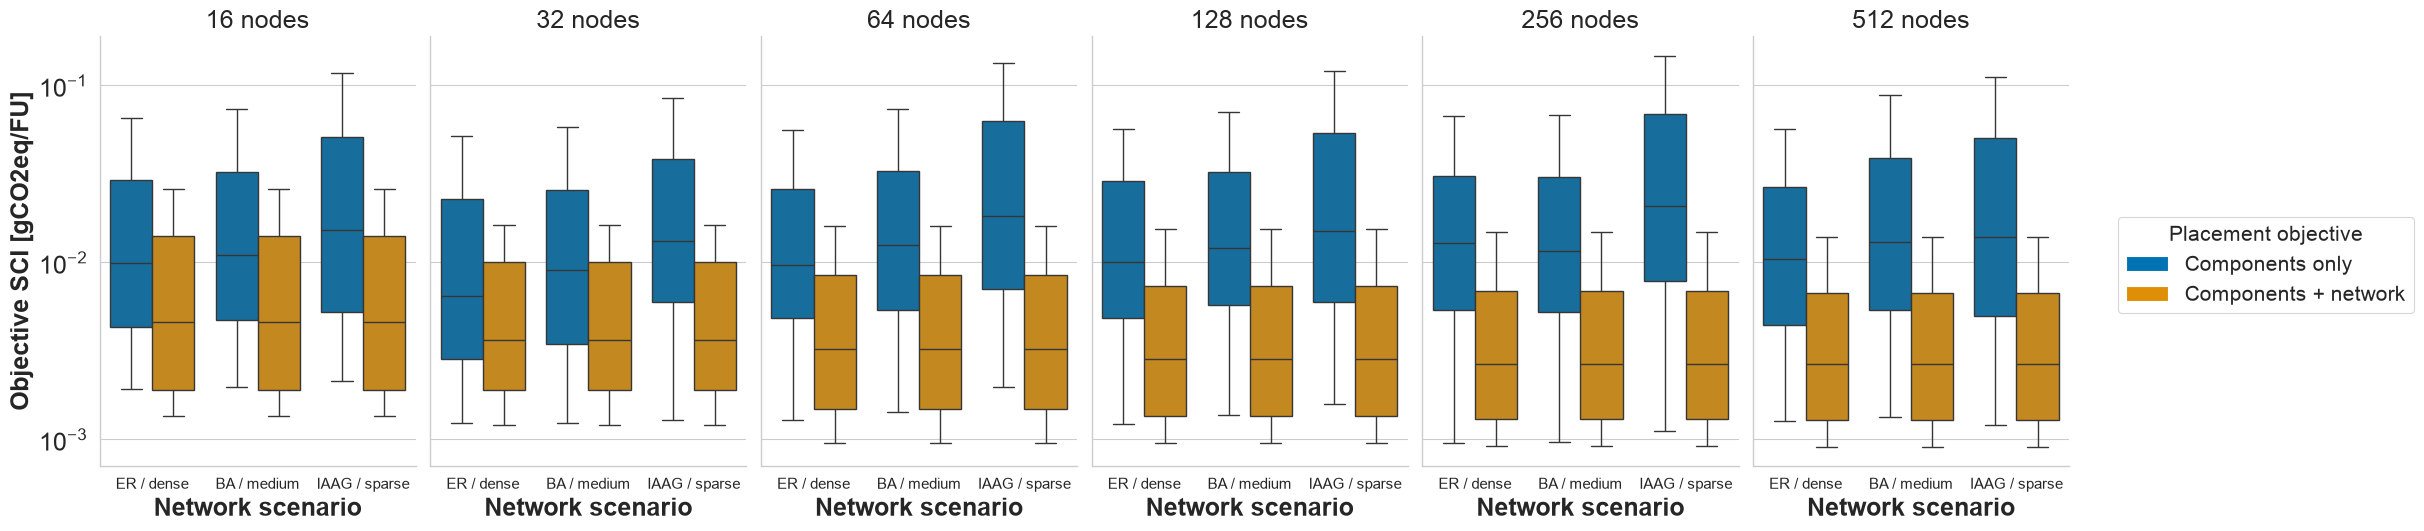

Saved: /Users/jacopomassa/GitHub/sci-aware-msa-placement/results-network/plots/objective-sci-by-network-topology-and-size.pdf


In [9]:
g = sns.catplot(
    data=data,
    x="network_scenario",
    y="objective_sci_g",
    hue="scope_label",
    col="infrastructure_size",
    kind="box",
    height=4.6,
    aspect=0.95,
    sharey=True,
    showfliers=False,
    legend=False,
    margin_titles=True,
)
g.figure.set_size_inches(24, 5.4)
g.set_axis_labels("Network scenario", "Objective SCI [gCO2eq/FU]")
g.set_titles(col_template="{col_name} nodes")
for ax in g.axes.flat:
    ax.set_yscale("log")
    ax.tick_params(axis="x", rotation=0, labelsize=11)
legend_handles = [
    Patch(facecolor=color, label=label)
    for color, label in zip(sns.color_palette("colorblind", 2), ["Components only", "Components + network"])
]
g.figure.legend(handles=legend_handles, title="Placement objective", loc="center left", bbox_to_anchor=(0.88, 0.5))
g.figure.tight_layout(rect=[0, 0, 0.87, 1])
save_plot("objective-sci-by-network-topology-and-size", g.fig)


## Component–network decomposition

Mean SCI is separated into its two contributions. The plot shows which strategies primarily reduce computing emissions and which limit traffic between nodes.


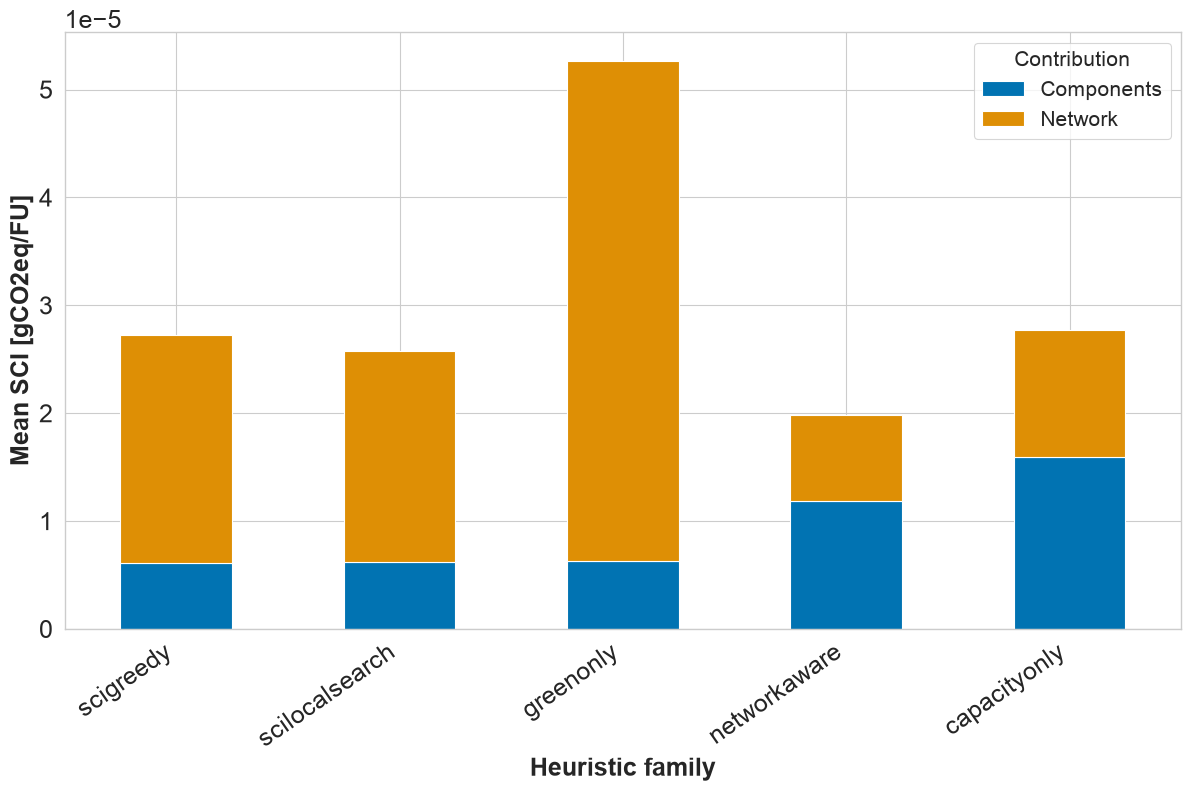

Saved: /Users/jacopomassa/GitHub/sci-aware-msa-placement/results-network/plots/sci-decomposition.pdf


In [10]:
decomposition = (
    data.groupby("heuristic_name")[["component_sci", "network_sci"]]
    .mean()
    .sort_values("component_sci")
)
ax = decomposition.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 8),
    color=sns.color_palette("colorblind", 2),
)
ax.set_xlabel("Heuristic family")
ax.set_ylabel("Mean SCI [gCO2eq/FU]")
ax.legend(["Components", "Network"], title="Contribution")
plt.xticks(rotation=35, ha="right")
save_plot("sci-decomposition")


## Network contribution by topology and size

The network share shows how much of total SCI comes from data transfer. Columns compare network size, the x-axis compares the fixed topology-density scenarios, and colours preserve the two placement objectives. Both RENATER profiles are pooled; use the route-profile filter to inspect one at a time.


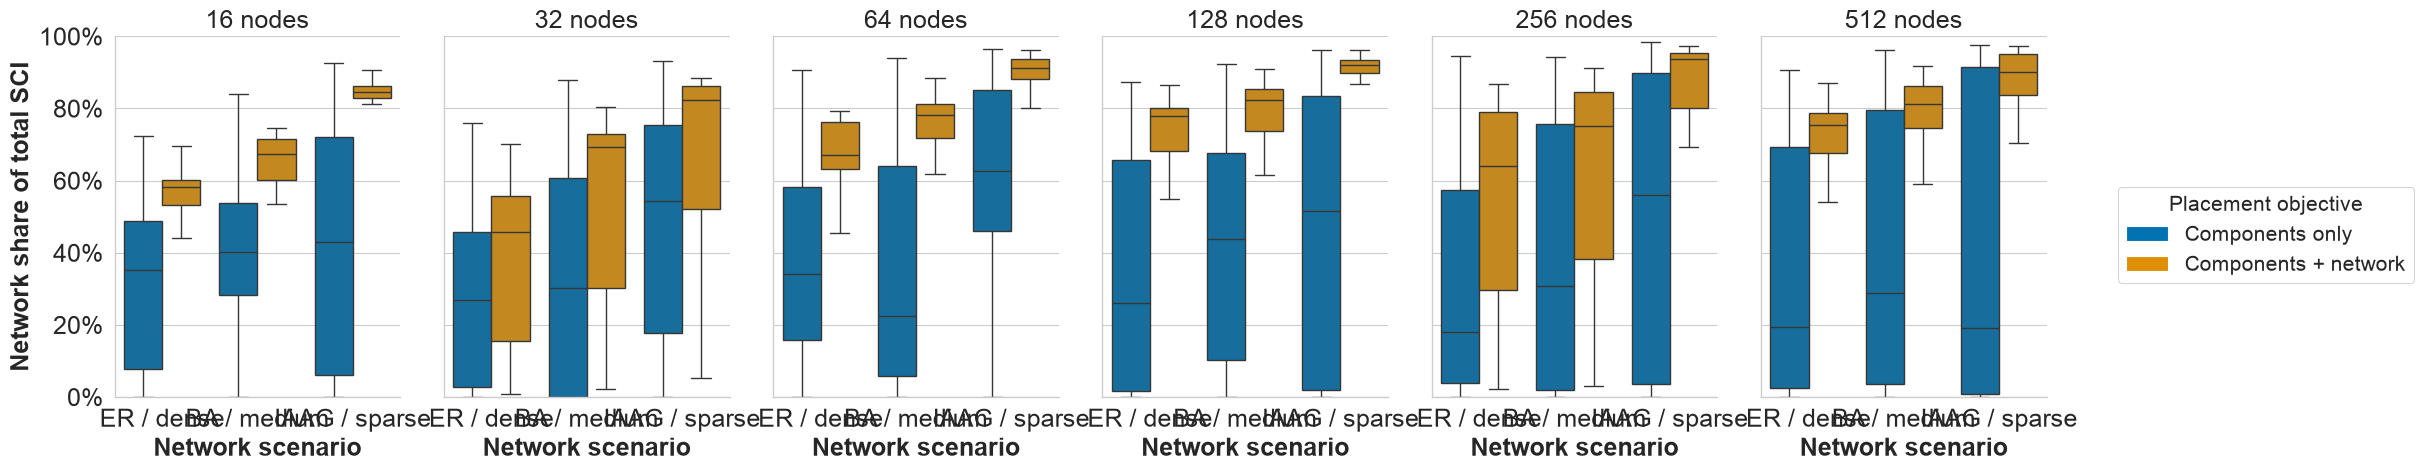

Saved: /Users/jacopomassa/GitHub/sci-aware-msa-placement/results-network/plots/network-share-by-topology-and-size.pdf


In [11]:
g = sns.catplot(
    data=data,
    x="network_scenario",
    y="network_share",
    hue="scope_label",
    col="infrastructure_size",
    kind="box",
    height=4.0,
    aspect=0.95,
    sharey=True,
    showfliers=False,
    legend=False,
    margin_titles=True,
)
g.figure.set_size_inches(24, 4.8)
g.set_axis_labels("Network scenario", "Network share of total SCI")
g.set_titles(col_template="{col_name} nodes")
g.set(ylim=(0, 1))
for ax in g.axes.flat:
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
legend_handles = [
    Patch(facecolor=color, label=label)
    for color, label in zip(sns.color_palette("colorblind", 2), ["Components only", "Components + network"])
]
g.figure.legend(handles=legend_handles, title="Placement objective", loc="center left", bbox_to_anchor=(0.88, 0.5))
g.figure.tight_layout(rect=[0, 0, 0.87, 1])
save_plot("network-share-by-topology-and-size", g.fig)


## Computation time

Runtime is aggregated by application size and heuristic family. The plot shows how computational cost grows, particularly for `scigreedy` and `scilocalsearch`.


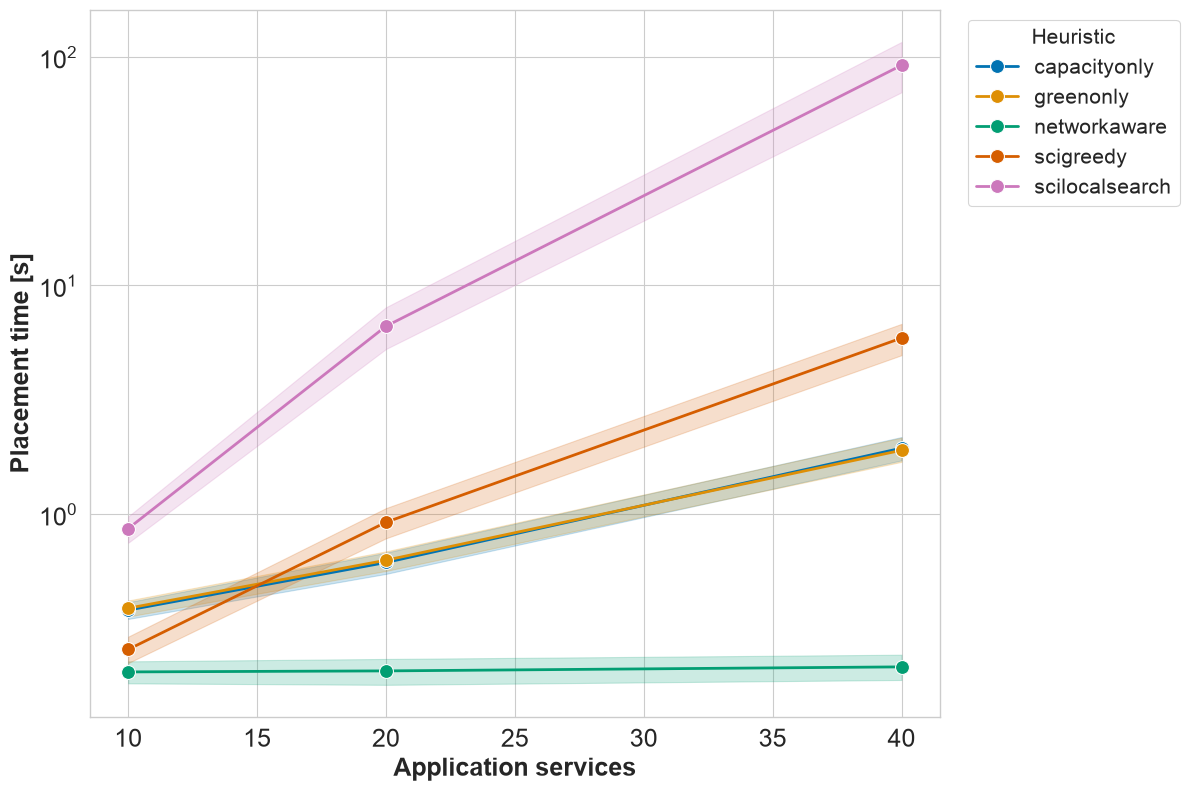

Saved: /Users/jacopomassa/GitHub/sci-aware-msa-placement/results-network/plots/placement-time-by-application-size.pdf


In [12]:
plt.figure(figsize=(12, 8))
sns.lineplot(
    data=data,
    x="application_size",
    y="time",
    hue="heuristic_name",
    marker="o",
    errorbar=ERRORBAR,
)
plt.xlabel("Application services")
plt.ylabel("Placement time [s]")
plt.yscale("log")
plt.legend(title="Heuristic", bbox_to_anchor=(1.02, 1), loc="upper left")
save_plot("placement-time-by-application-size")


## Placement distribution

The number of nodes used measures how strongly each strategy concentrates or distributes services. Lower values may reduce network SCI, while broader distributions may exploit greener nodes or greater capacity.


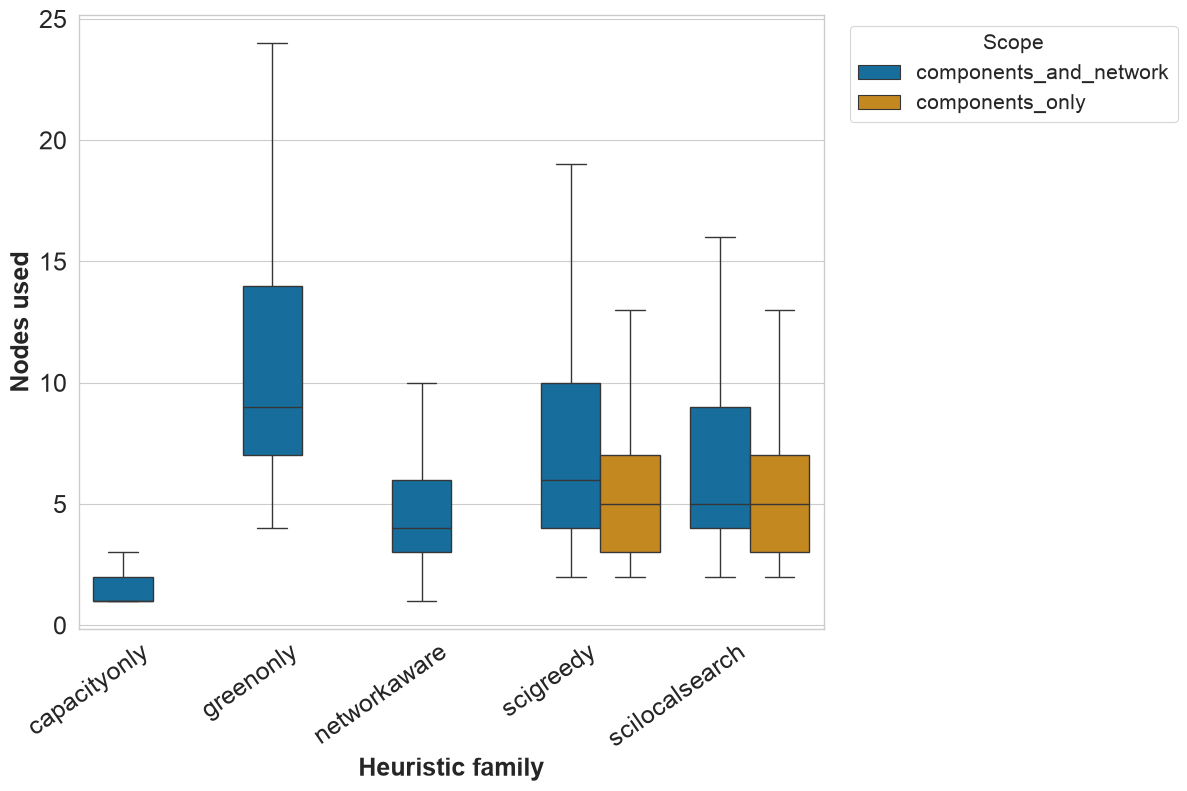

Saved: /Users/jacopomassa/GitHub/sci-aware-msa-placement/results-network/plots/nodes-used-by-heuristic.pdf


In [13]:
plt.figure(figsize=(12, 8))
sns.boxplot(
    data=data,
    x="heuristic_name",
    y="nodes_used",
    hue="scope",
    showfliers=False,
)
plt.xlabel("Heuristic family")
plt.ylabel("Nodes used")
plt.xticks(rotation=35, ha="right")
plt.legend(title="Scope", bbox_to_anchor=(1.02, 1), loc="upper left")
save_plot("nodes-used-by-heuristic")


## Relative placement quality

For each scenario, total SCI is divided by the best value found for that same scenario. A ratio of 1 identifies the best result; larger values measure the distance from it.


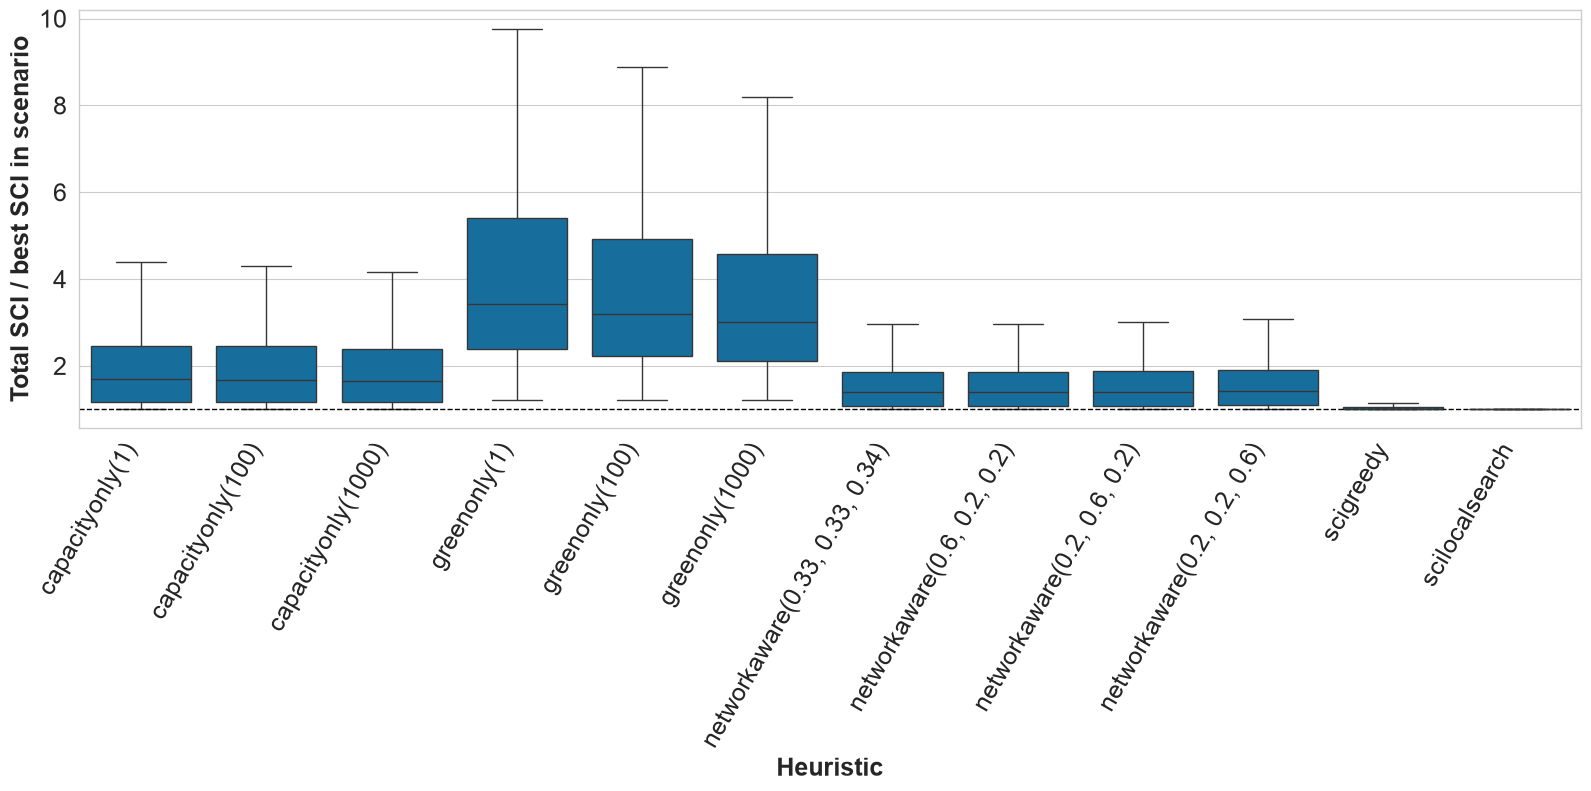

Saved: /Users/jacopomassa/GitHub/sci-aware-msa-placement/results-network/plots/relative-total-sci.pdf


In [14]:
scenario_columns = [
    "seed",
    "application_topology",
    "application_size",
    "infrastructure_topology",
    "infrastructure_density",
    "infrastructure_size",
    "scope",
    "route_profile",
    "include_network_embodied",
]
best_sci = data.groupby(scenario_columns, dropna=False)["total_sci"].transform("min")
data["relative_total_sci"] = data["total_sci"] / best_sci

plt.figure(figsize=(16, 8))
sns.boxplot(
    data=data,
    x="heuristic_label",
    y="relative_total_sci",
    showfliers=False,
)
plt.axhline(1.0, color="black", linestyle="--", linewidth=1)
plt.xlabel("Heuristic")
plt.ylabel("Total SCI / best SCI in scenario")
plt.xticks(rotation=60, ha="right")
save_plot("relative-total-sci")
